# Heteroskedasticity and clustering in Kalman Filter innovations for pairs trading

Research notebook implementing the empirical pipeline from the research plan: a Kalman Filter (KF)
baseline for the dynamic hedge ratio, diagnosis of ARCH/clustering effects in the innovations
(**H1**), a GARCH-filtered z-score (order/distribution chosen via grid search) compared against the
plain homoskedastic KF z-score, z-score calibration tests (**H2**), and a walk-forward backtest using
the same trading rule for both models — evaluated exclusively on **risk metrics** (**H3**), not P&L.

**What this version implements:** a "no correction" baseline (standard homoskedastic KF) vs. a
post-hoc GARCH model (grid search over vol type/p/o/q/distribution, selected by BIC). The EWMA
benchmark and every pure-performance metric (Sharpe, PSR, DSR, Calmar, equity curves) have been
dropped to keep the notebook focused on a single question. Models 2 (Innovation-based Adaptive
Estimation / Sage-Husa) and 3 (GARCH-in-KF) from the research plan are left for a follow-up version.

**Rigor of the setup:** cointegration screening (Engle-Granger + Johansen) over a cross-sector
universe of candidate pairs, fully walk-forward estimation and backtesting (no look-ahead: every
refit uses only data prior to the point at which it is applied), the same trading rule for both
models to isolate the effect of the z-score construction alone, and significance assessed via block
bootstrap.

**This version's focus:** the H3 section below asks only the risk-management question that matters
for a pairs-trading book — **does correcting for heteroskedastic KF innovations reduce the realized
risk of the strategy** (volatility, tail losses, drawdowns) relative to the homoskedastic baseline?
Whether it also changes P&L is deliberately out of scope here.

**New in this version:** H2 calibration now tests GARCH's z-score against the distribution the grid
search actually fit (Normal/t/skewt), not always Normal (Section 5); H3 adds a robustness check
restricted to pairs that also pass a stricter cointegration threshold (Section 9), two pooled
significance tests across all pairs (Section 8), and a diagnostic into why GARCH sometimes extends
drawdown duration even when it shrinks max drawdown (Section 10). A new Section 6 asks a narrower,
better-powered question than the H3 backtest: whether GARCH's variance forecast is itself more
accurate than the baseline's, tested directly via QLIKE loss and a Diebold-Mariano test rather than
through the noisier lens of a backtested strategy.


In [1]:
# --- Setup (Colab-compatible): install missing packages if needed ---
try:
    import arch, statsmodels, yfinance  # noqa: F401
except ImportError:
    import sys
    !{sys.executable} -m pip install -q arch statsmodels yfinance plotly


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 4.9 MB/s eta 0:00:00


In [2]:
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.optimize import minimize
from scipy.stats import norm, kstest
from statsmodels.stats.diagnostic import het_arch
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from arch import arch_model
import yfinance as yf

warnings.filterwarnings("ignore")
np.set_printoptions(suppress=True)

# Consistent color coding for the two variance models, used in every plot below.
MODEL_COLORS = {"base": "#7f7f7f", "garch": "#d62728"}
MODEL_LABELS = {"base": "Baseline (homoskedastic)", "garch": "GARCH"}


In [3]:
# ================================ CONFIG ================================
# Every pipeline parameter lives here: edit only this cell to change the
# universe, the sample period, the estimation windows or the trading rule.

CONFIG = dict(
    # --- candidate universe: broader cross-sector set (50 pairs), pre-screened by the
    # user's own separate pipeline, substituted in place of the original 10-pair list.
    PAIR_CANDIDATES=[
        ("AEP", "EIX"),
        ("CMI", "SNA"),
        ("ETN", "TT"),
        ("TXT", "XYL"),
        ("FISV", "GL"),
        ("IBM", "TDY"),
        ("MSI", "TDY"),
        ("MSFT", "VRSN"),
        ("HON", "SWK"),
        ("BAX", "CI"),
        ("NOC", "PNR"),
        ("AEP", "WEC"),
        ("AMAT", "TER"),
        ("ABT", "CVS"),
        ("IFF", "NEM"),
        ("AEE", "DUK"),
        ("AON", "SPGI"),
        ("CCI", "PLD"),
        ("AEE", "ETR"),
        ("O", "VTR"),
        ("MDT", "RVTY"),
        ("FAST", "VRSK"),
        ("MDT", "UNH"),
        ("DE", "HUBB"),
        ("DVN", "EQT"),
        ("ECH", "EWA"),
        ("FAST", "MAS"),
        ("INTU", "QCOM"),
        ("AEE", "SO"),
        ("APD", "VMC"),
        ("AEP", "XEL"),
        ("AIG", "FIS"),
        ("EWA", "EWL"),
        ("AMGN", "LH"),
        ("GD", "NSC"),
        ("LEN", "LOW"),
        ("INTU", "MSI"),
        ("AMGN", "CRL"),
        ("AMAT", "MU"),
        ("CTSH", "TEL"),
        ("APD", "MLM"),
        ("INTU", "TER"),
        ("BAX", "TMO"),
        ("TT", "WAB"),
        ("GE", "ITW"),
        ("JPM", "NTRS"),
        ("BDX", "SYK"),
        ("CCI", "SPG"),
        ("AME", "LHX"),
        ("EWG", "EWT"),
    ],

    START_DATE="2015-01-01",
    END_DATE="2026-09-22",   # spans the 2020 COVID shock and the 2022 rate-hike cycle

    COINT_ALPHA=0.10,          # p-value threshold for Engle-Granger / Johansen criterion
                                # (relaxed from 0.05 -> 0.10: on real data a 5% threshold left
                                # very few pairs in the selected universe -- see the markdown
                                # note below on why this is a defensible relaxation, not p-hacking)
    COINT_RECENT_YEARS=4,      # cointegration over a 10+ year sample often does not hold up
                                # to structural breaks (regime shifts, spin-offs, M&A...): a
                                # pair is selected if cointegrated over the FULL sample OR over
                                # the last COINT_RECENT_YEARS years (the period most relevant to
                                # the out-of-sample trading that will actually happen)

    TRAIN_WINDOW=504,        # ~2 trading years: initial estimation / refitting window
    REFIT_FREQ=126,           # ~6 months: walk-forward re-estimation frequency (KF: Q,R; GARCH: params)

    ENTRY_Z=2.0,
    EXIT_Z=0.5,
    STOP_Z=4.0,
    COST_BPS=2.0,             # transaction cost per unit of turnover, per leg

    N_BOOTSTRAP=1000,
    BOOTSTRAP_BLOCK=20,
    CVAR_ALPHA=0.05,          # tail probability for historical CVaR / Expected Shortfall

    RANDOM_SEED=42,
)


## 1. Data and cointegration screening

Download prices for the candidate universe and keep only the pairs that are actually cointegrated
(Engle-Granger *and* Johansen agree) before moving on to KF estimation — cointegration is verified,
not assumed.

**Why relax `COINT_ALPHA` to 0.10 and why fix the Johansen critical value:** on the real-data run,
only a handful of pairs passed the original 5% threshold, and even after relaxing the Engle-Granger
side the Johansen trace test was still being compared against its hardcoded 95% critical value —
so raising `COINT_ALPHA` only loosened half of the joint (AND) test. `_eg_johansen` below fixes that
by picking the Johansen critical-value column (90% / 95% / 99%, the only ones `coint_johansen`
tabulates) that matches the current `alpha`, so both legs of the test stay consistently calibrated.
A 10% threshold is a real, disclosed relaxation of statistical stringency — not a way to manufacture
more "significant" pairs — and it is reported as such in every table below.

In [4]:
def _eg_johansen(y, x, alpha):
    '''Engle-Granger in BOTH directions (the test is not symmetric in finite samples: the
    better of the two p-values is used) + Johansen, on a single window.
    The Johansen critical value now follows the same `alpha` as Engle-Granger instead of
    staying fixed at 95% (that was the real bottleneck, not EG): alpha>=0.10 -> 90% critical
    value, alpha>=0.05 -> 95%, otherwise 99%.'''
    _, eg_pval_yx, _ = coint(y, x)
    _, eg_pval_xy, _ = coint(x, y)
    eg_pval = min(eg_pval_yx, eg_pval_xy)

    df = pd.DataFrame({"y": y, "x": x})
    jres = coint_johansen(df, det_order=0, k_ar_diff=1)
    crit_col = 0 if alpha >= 0.10 else (1 if alpha >= 0.05 else 2)  # columns: 90% / 95% / 99%
    trace_stat, crit_value = jres.lr1[0], jres.cvt[0, crit_col]

    eg_ok = eg_pval < alpha
    johansen_ok = trace_stat > crit_value
    return dict(eg_pvalue=eg_pval, eg_ok=eg_ok, trace=trace_stat, crit95=crit_value,
                johansen_ok=johansen_ok, ok=eg_ok and johansen_ok)


def screen_cointegration(log_prices, pairs, alpha=0.05, recent_years=4):
    '''A pair is selected if cointegrated (bidirectional EG + Johansen, both at level `alpha`)
    over the FULL sample OR over the last `recent_years` years.
    Rationale: over 10+ years, cointegration relationships often break down due to structural
    breaks (regime shifts, M&A, spin-offs...) even for economically sensible pairs; the recent
    period is also the one most relevant for out-of-sample trading.'''
    recent_n = min(len(log_prices), int(252 * recent_years))
    rows = []
    selected = []
    for y_t, x_t in pairs:
        y_full, x_full = log_prices[y_t].values, log_prices[x_t].values
        y_rec, x_rec = y_full[-recent_n:], x_full[-recent_n:]

        full = _eg_johansen(y_full, x_full, alpha)
        recent = _eg_johansen(y_rec, x_rec, alpha)
        ok = full["ok"] or recent["ok"]

        rows.append({"pair": f"{y_t}/{x_t}",
                      "EG_pvalue_full": full["eg_pvalue"], "Johansen_ok_full": full["johansen_ok"],
                      "full_ok": full["ok"],
                      "EG_pvalue_recent": recent["eg_pvalue"], "Johansen_ok_recent": recent["johansen_ok"],
                      "recent_ok": recent["ok"],
                      "selected": ok})
        if ok:
            selected.append((y_t, x_t))

    table = pd.DataFrame(rows).sort_values(
        by=["selected", "EG_pvalue_recent"], ascending=[False, True]).reset_index(drop=True)
    return table, selected


def download_prices(pairs, start, end):
    tickers = sorted(set(t for pair in pairs for t in pair))
    raw = yf.download(tickers, start=start, end=end, progress=False)["Close"]
    if isinstance(raw, pd.Series):
        raw = raw.to_frame()
    return raw.dropna(how="any")


prices = download_prices(CONFIG["PAIR_CANDIDATES"], CONFIG["START_DATE"], CONFIG["END_DATE"])
log_prices = np.log(prices)
print(f"Downloaded data: {prices.shape[0]} observations, {prices.shape[1]} tickers.")
prices.tail()


Downloaded data: 2945 observations, 82 tickers.


Ticker,ABT,AEE,AEP,AIG,AMAT,AME,AMGN,AON,APD,BAX,...,TXT,UNH,VMC,VRSK,VRSN,VTR,WAB,WEC,XEL,XYL
Date,,,,,,,,,,,,,,,,,,,,,
2026-09-15,102.029999,103.019997,120.610001,75.480003,421.170013,234.449997,375.649994,304.670013,290.559998,23.709999,...,80.720001,375.929993,249.199997,180.080002,297.260010,88.559998,278.119995,103.510002,72.489998,107.500000
2026-09-16,102.360001,103.040001,120.690002,76.070000,415.380005,232.190002,376.350006,300.570007,287.079987,23.530001,...,80.709999,375.260010,244.300003,181.750000,298.459991,88.209999,276.369995,103.379997,72.709999,107.269997
2026-09-17,102.230003,103.900002,121.620003,75.680000,417.399994,234.320007,379.779999,296.049988,286.119995,23.020000,...,80.910004,375.209991,244.500000,176.479996,302.049988,87.709999,278.820007,104.730003,73.629997,107.599998
2026-09-18,102.610001,102.230003,120.000000,75.330002,444.570007,237.639999,385.649994,295.640015,284.179993,22.799999,...,79.690002,376.899994,240.830002,175.410004,303.119995,86.690002,280.230011,103.169998,72.300003,107.559998
2026-09-21,102.980003,101.830002,120.029999,74.540001,464.239990,241.229996,393.160004,290.820007,279.459991,22.930000,...,79.410004,377.559998,246.199997,172.020004,308.179993,87.029999,283.380005,103.480003,71.849998,107.239998


In [5]:
coint_table, SELECTED_PAIRS = screen_cointegration(log_prices, CONFIG["PAIR_CANDIDATES"],
                                                     CONFIG["COINT_ALPHA"], CONFIG["COINT_RECENT_YEARS"])
print(f"Selected pairs (cointegrated over the full sample or the last "
      f"{CONFIG['COINT_RECENT_YEARS']} years, alpha={CONFIG['COINT_ALPHA']}): {SELECTED_PAIRS}")
display(coint_table)  # always shown, even if SELECTED_PAIRS turns out to be empty

assert len(SELECTED_PAIRS) > 0, (
    "No candidate pair turned out to be cointegrated (neither over the full sample nor "
    "over the recent period). Check EG_pvalue_recent in coint_table for the pairs closest "
    "to the threshold, then widen PAIR_CANDIDATES, raise COINT_ALPHA, or shorten "
    "COINT_RECENT_YEARS in CONFIG."
)


Selected pairs (cointegrated over the full sample or the last 4 years, alpha=0.1): [('BAX', 'CI'), ('AON', 'SPGI'), ('CCI', 'PLD'), ('MDT', 'RVTY'), ('FAST', 'MAS'), ('AMGN', 'LH'), ('GD', 'NSC'), ('GE', 'ITW'), ('CCI', 'SPG')]


,pair,EG_pvalue_full,Johansen_ok_full,full_ok,EG_pvalue_recent,Johansen_ok_recent,recent_ok,selected
0,GE/ITW,0.657977,False,False,0.007139,True,True,True
1,GD/NSC,0.743380,False,False,0.025047,True,True,True
2,BAX/CI,0.342657,False,False,0.059704,True,True,True
3,CCI/PLD,0.940807,False,False,0.061136,True,True,True
4,CCI/SPG,0.542982,False,False,0.088501,True,True,True
5,AON/SPGI,0.057443,True,True,0.127383,False,False,True
6,MDT/RVTY,0.046656,True,True,0.210527,False,False,True
7,AMGN/LH,0.032735,True,True,0.291538,False,False,True
8,FAST/MAS,0.003263,True,True,0.309494,False,False,True
9,MDT/UNH,0.273126,False,False,0.094900,False,False,False


## 2. Baseline Kalman Filter (dynamic hedge ratio, walk-forward)

Local-level KF: state = hedge ratio $\beta_t$ (random walk), observation $y_t = \beta_t x_t + v_t$.
$(Q,R)$ are estimated via MLE on the initial training window and then **re-estimated periodically**
(`REFIT_FREQ`) on a trailing window — never using data that lies in the future relative to the point
of refitting. This is the object whose innovations $e_t$ are examined for heteroskedasticity in the
next section: everything downstream (GARCH, the z-score, the backtest) operates on this same KF
innovation series, so any effect found is attributable to how the innovation *variance* is modeled,
not to a different hedge-ratio estimate.

In [6]:
def kf_filter_tv(y, x, Q_arr, R_arr, beta0, P0):
    '''KF recursion with (Q,R) allowed to vary over time (piecewise-constant).'''
    n = len(y)
    beta_pred = np.empty(n); P_pred = np.empty(n)
    beta_filt = np.empty(n); P_filt = np.empty(n)
    e = np.empty(n); S = np.empty(n)

    beta_prev, P_prev = beta0, P0
    for t in range(n):
        Q, R = Q_arr[t], R_arr[t]
        b_pred = beta_prev
        p_pred = P_prev + Q
        et = y[t] - b_pred * x[t]
        st = max(x[t] ** 2 * p_pred + R, 1e-12)
        K = p_pred * x[t] / st
        b_filt = b_pred + K * et
        p_filt = (1.0 - K * x[t]) * p_pred

        beta_pred[t], P_pred[t] = b_pred, p_pred
        beta_filt[t], P_filt[t] = b_filt, p_filt
        e[t], S[t] = et, st
        beta_prev, P_prev = b_filt, p_filt

    return dict(beta_pred=beta_pred, P_pred=P_pred, beta_filt=beta_filt,
                P_filt=P_filt, e=e, S=S)


def kf_negloglik(log_params, y, x, beta0, P0):
    logQ, logR = log_params
    Q, R = np.exp(logQ), np.exp(logR)
    out = kf_filter_tv(y, x, np.full(len(y), Q), np.full(len(y), R), beta0, P0)
    e, S = out["e"], out["S"]
    return 0.5 * np.sum(np.log(2 * np.pi * S) + e ** 2 / S)


def fit_kf_mle(y, x, P0=1.0, q0=1e-4, r0=1e-2):
    '''MLE of (Q,R) via L-BFGS-B on the log-parameters (guarantees positivity).'''
    beta0 = float(np.polyfit(x, y, 1)[0])  # initial prior: OLS hedge ratio on the window
    res = minimize(kf_negloglik, np.log([q0, r0]), args=(y, x, beta0, P0),
                    method="L-BFGS-B", bounds=[(-25, 5), (-25, 5)])
    Q_hat, R_hat = np.exp(res.x)
    return Q_hat, R_hat, beta0, P0


def build_walkforward_kf(y, x, train_window, refit_freq):
    '''Piecewise-constant (Q,R), re-estimated every `refit_freq` steps on the preceding trailing
    window; the filter itself runs once, continuously, over the whole sample.'''
    n = len(y)
    Q_arr = np.empty(n); R_arr = np.empty(n)

    Q0, R0, beta0, P0 = fit_kf_mle(y[:train_window], x[:train_window])
    Q_arr[:train_window] = Q0
    R_arr[:train_window] = R0

    t = train_window
    while t < n:
        block_end = min(t + refit_freq, n)
        est_start = max(0, t - train_window)
        Qn, Rn, _, _ = fit_kf_mle(y[est_start:t], x[est_start:t])
        Q_arr[t:block_end] = Qn
        R_arr[t:block_end] = Rn
        t = block_end

    out = kf_filter_tv(y, x, Q_arr, R_arr, beta0, P0)
    out["Q_arr"], out["R_arr"] = Q_arr, R_arr
    return out


kf_results = {}
DEGENERATE_STD_FLOOR = 1e-5  # below this threshold the innovation is numerical noise, not
                              # signal (typical of near-identical pairs, e.g. dual-class shares)
for y_t, x_t in SELECTED_PAIRS:
    y = log_prices[y_t].values
    x = log_prices[x_t].values
    out = build_walkforward_kf(y, x, CONFIG["TRAIN_WINDOW"], CONFIG["REFIT_FREQ"])
    e_std = out["e"].std()
    if e_std < DEGENERATE_STD_FLOOR:
        print(f"{y_t}/{x_t}: DROPPED - innovation std={e_std:.2e}, too close to zero "
              f"(near-collinear pair: the z-score would be numerical noise, not signal).")
        continue
    kf_results[(y_t, x_t)] = out
    print(f"{y_t}/{x_t}: KF fitted. innovation std={e_std:.4f}")

assert len(kf_results) > 0, "No selected pair survived the numerical-degeneracy check."


BAX/CI: KF fitted. innovation std=0.0829
AON/SPGI: KF fitted. innovation std=0.0341
CCI/PLD: KF fitted. innovation std=0.0424
MDT/RVTY: KF fitted. innovation std=0.0290
FAST/MAS: KF fitted. innovation std=0.0323
AMGN/LH: KF fitted. innovation std=0.0413
GD/NSC: KF fitted. innovation std=0.0656
GE/ITW: KF fitted. innovation std=0.0459
CCI/SPG: KF fitted. innovation std=0.0258


## 3. H1 diagnosis — ARCH effects in the KF innovations

Engle's ARCH-LM test, computed on the **out-of-sample** portion (after the initial training window),
so in-sample fit is never mistaken for genuine predictive evidence. (A Ljung-Box test on the squared
innovations was also run in an earlier version of this notebook and agreed with ARCH-LM on every
single pair, so only ARCH-LM -- the test named specifically for this null -- is kept here.)

**How to read this:** a significant ARCH-LM p-value at the 5% level means the null of "no volatility
clustering in the innovations" is rejected for that pair — i.e. evidence supporting **H1**. This is a
per-pair test, not a single omnibus test, so when interpreting how many pairs show significant
clustering out of the total tested, keep the multiple-testing problem in mind (see the bootstrap
significance section further down for the same caveat applied to H3).

In [7]:
def arch_lm_test(e, nlags=10):
    e = np.asarray(e, dtype=float)
    lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(e, nlags=nlags)
    return dict(lm_stat=lm_stat, lm_pvalue=lm_pvalue, f_stat=f_stat, f_pvalue=f_pvalue)


h1_rows = []
for (y_t, x_t), out in kf_results.items():
    e_oos = out["e"][CONFIG["TRAIN_WINDOW"]:]
    arch_res = arch_lm_test(e_oos)
    h1_rows.append({"pair": f"{y_t}/{x_t}",
                     "ARCH_LM_pvalue": arch_res["lm_pvalue"],
                     "ARCH_effect_significant_5pct": arch_res["lm_pvalue"] < 0.05})

h1_table = pd.DataFrame(h1_rows)
h1_table


,pair,ARCH_LM_pvalue,ARCH_effect_significant_5pct
0,BAX/CI,1.630521e-06,True
1,AON/SPGI,3.092970e-59,True
2,CCI/PLD,1.079920e-30,True
3,MDT/RVTY,4.298150e-04,True
4,FAST/MAS,2.734352e-01,False
5,AMGN/LH,7.248413e-67,True
6,GD/NSC,4.577540e-05,True
7,GE/ITW,5.945848e-15,True
8,CCI/SPG,7.938664e-159,True


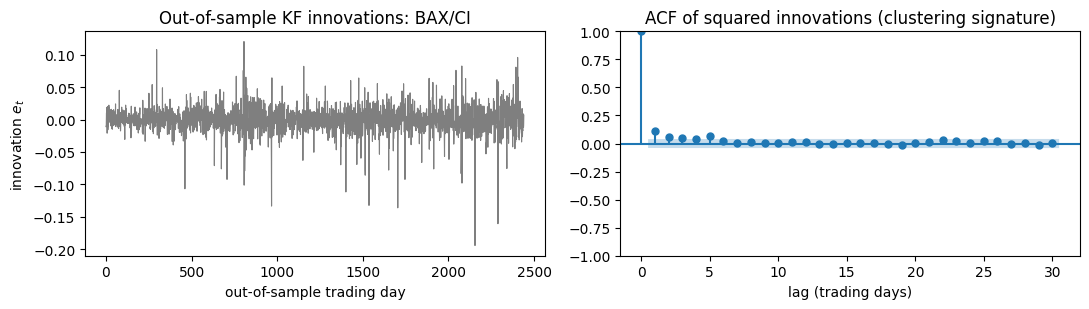

In [8]:
# Illustrative ACF of the squared innovations for the first pair remaining after the KF step
if kf_results:
    y_t, x_t = next(iter(kf_results))
    e_oos = kf_results[(y_t, x_t)]["e"][CONFIG["TRAIN_WINDOW"]:]
    from statsmodels.graphics.tsaplots import plot_acf
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    axes[0].plot(e_oos, color=MODEL_COLORS["base"], lw=0.8)
    axes[0].set_title(f"Out-of-sample KF innovations: {y_t}/{x_t}")
    axes[0].set_xlabel("out-of-sample trading day"); axes[0].set_ylabel("innovation $e_t$")
    plot_acf(e_oos ** 2, lags=30, ax=axes[1])
    axes[1].set_title("ACF of squared innovations (clustering signature)")
    axes[1].set_xlabel("lag (trading days)")
    plt.tight_layout()
    plt.show()


## 4. GARCH model selection via grid search

The `GarchGridSearchPro` class is the one supplied by the user (`model_selection_gridsearch_class.py`),
with **one surgical change**: `load_data` now also accepts a precomputed series (here, the KF
innovations) instead of always downloading from yfinance. Everything else — the grid loop
(vol type / distribution / p / o / q), the validity filters, BIC-based selection, `show_top_models`
— is unchanged.

The order/distribution is selected **once** per pair on the initial training window; the
**parameters** are then re-estimated every `REFIT_FREQ` steps on a trailing window (same
walk-forward principle as the KF), and the conditional variance is extended day by day using only
the innovations realized so far.

In [9]:
class GarchGridSearchPro:
    '''Grid search over GARCH/EGARCH families x distributions x orders (p,o,q), selected by BIC.
    Adapted from the user's original script: load_data now also accepts `series` (e.g. the KF
    innovations) in place of a yfinance download.'''

    def __init__(self, ticker=None, start_date=None, end_date=None, series=None):
        self.ticker = ticker
        self.start = start_date
        self.end = end_date
        self.series = series  # NEW: optional precomputed series (e.g. KF innovations)
        self.data = None
        self.results_table = None
        self.best_model_result = None
        self._scale = 100.0

    def load_data(self):
        if self.series is not None:
            # --- NEW PATH: use an already-available series (e.g. KF innovations) ---
            raw = pd.DataFrame({"log_ret": pd.Series(self.series).astype(float)}).dropna()
            std = raw["log_ret"].std()
            scale = 100.0 / std if std > 0 else 1.0
            raw["scaled_ret"] = raw["log_ret"] * scale
            self.data = raw
            self._scale = scale
            return

        # --- ORIGINAL PATH: unchanged from the script the user provided ---
        print(f"--- Downloading data for {self.ticker} ---")
        try:
            raw = yf.download(self.ticker, start=self.start, end=self.end, progress=False)
            if isinstance(raw.columns, pd.MultiIndex):
                if self.ticker in raw.columns.levels[1]:
                    raw = raw.xs(self.ticker, level=1, axis=1)
                else:
                    raw = raw.iloc[:, 0].to_frame(name="Adj Close")
            elif "Adj Close" in raw.columns:
                raw = raw[["Adj Close"]]
            else:
                raw = raw.iloc[:, 0].to_frame(name="Adj Close")
            raw["log_ret"] = np.log(raw.iloc[:, 0] / raw.iloc[:, 0].shift(1))
            self.data = raw.dropna()
            self.data["scaled_ret"] = self.data["log_ret"] * 100
            self._scale = 100.0
        except Exception as e:
            print(f"Error loading data: {e}")

    def run_search(self):
        if self.data is None:
            self.load_data()

        dists = ["Normal", "t", "skewt"]
        ps, qs, os_ = [1, 2], [1, 2], [0, 1]
        vol_types = ["GARCH", "EGARCH"]

        results_list = []
        total_combos = 0
        for vol in vol_types:
            for dist in dists:
                for p in ps:
                    for q in qs:
                        for o in os_:
                            model_name = ("GARCH (Std)" if o == 0 else "GJR-GARCH") if vol == "GARCH" \
                                else f"EGARCH (o={o})"
                            try:
                                am = arch_model(self.data["scaled_ret"], vol=vol, p=p, o=o, q=q,
                                                 dist=dist, mean="Constant")
                                res = am.fit(disp="off")
                                results_list.append({"Model": model_name, "Dist": dist, "vol": vol,
                                                      "p": p, "o": o, "q": q, "AIC": res.aic,
                                                      "BIC": res.bic, "LogLik": res.loglikelihood,
                                                      "Result_Object": res})
                                total_combos += 1
                            except Exception:
                                pass

        results_df = pd.DataFrame(results_list)
        if results_df.empty:
            print("No model managed to converge.")
            return
        self.results_table = results_df.sort_values(by="BIC").reset_index(drop=True)
        self.best_model_result = self.results_table.iloc[0]["Result_Object"]
        print(f"--- Grid search complete: {total_combos} combinations tested ---")

    def show_top_models(self, n=5):
        if self.results_table is None:
            return
        cols = ["Model", "Dist", "p", "o", "q", "BIC", "AIC"]
        print(self.results_table[cols].head(n))
        best = self.results_table.iloc[0]
        print(f"Winner: {best['Model']}  p={best['p']} o={best['o']} q={best['q']}  Dist={best['Dist']}")

    def conditional_volatility(self):
        cv = self.best_model_result.conditional_volatility / self._scale
        return pd.Series(cv, index=self.data.index)


In [10]:
def garch_recursion(shock, omega, alpha, beta, gamma=0.0, h_seed=None):
    '''GARCH(1,1) / GJR-GARCH(1,1,1): h_t = omega + alpha*shock_{t-1}^2
    + gamma*shock_{t-1}^2*1[shock_{t-1}<0] + beta*h_{t-1}.'''
    n = len(shock)
    h = np.empty(n)
    h[0] = h_seed if h_seed is not None else omega / max(1e-8, 1 - alpha - beta - 0.5 * gamma)
    for t in range(1, n):
        s_prev = shock[t - 1]
        ind = 1.0 if s_prev < 0 else 0.0
        h[t] = omega + alpha * s_prev ** 2 + gamma * ind * s_prev ** 2 + beta * h[t - 1]
    return h


def egarch_recursion(shock, omega, alpha, beta, gamma=0.0, h_seed=None):
    '''EGARCH(1,1,1), using the `arch` package's convention:
    ln(h_t) = omega + beta*ln(h_{t-1}) + alpha*(|z_{t-1}| - sqrt(2/pi)) + gamma*z_{t-1}.'''
    n = len(shock)
    logh = np.empty(n)
    logh[0] = np.log(max(h_seed if h_seed is not None else np.var(shock), 1e-8))
    c = np.sqrt(2.0 / np.pi)
    for t in range(1, n):
        h_prev = np.exp(logh[t - 1])
        z_prev = shock[t - 1] / np.sqrt(max(h_prev, 1e-12))
        logh[t] = omega + beta * logh[t - 1] + alpha * (abs(z_prev) - c) + gamma * z_prev
    return np.exp(logh)


def recursion_from_fit(res, vol, shock, h_seed=None):
    p = res.params
    omega, alpha, beta = p["omega"], p["alpha[1]"], p["beta[1]"]
    gamma = p["gamma[1]"] if "gamma[1]" in p.index else 0.0
    if vol == "EGARCH":
        return egarch_recursion(shock, omega, alpha, beta, gamma, h_seed=h_seed)
    return garch_recursion(shock, omega, alpha, beta, gamma, h_seed=h_seed)
# Note: this manual recursion has been validated against `res.conditional_volatility` from
# the `arch` package (in-sample relative error < 1e-14 across all 4 vol/o variants).


def build_garch_zscore(e, train_window, refit_freq):
    '''Selects the order/distribution once (grid search on the training window), then
    re-estimates only the parameters every `refit_freq` steps and extends the conditional
    variance day by day using realized innovations (no look-ahead).
    Also returns the fitted distribution object (`arch.univariate` Normal/StudentsT/SkewStudent)
    and, per re-fit block, its shape parameters -- e.g. (eta, lambda) for skewt -- so that
    calibration testing downstream can use the distribution GARCH actually assumes for the
    z-score, instead of always assuming Normal (see the H2 section below for why this matters).'''
    n = len(e)
    h = np.full(n, np.nan)

    gs = GarchGridSearchPro(series=pd.Series(e[:train_window]))
    gs.run_search()
    gs.show_top_models(5)
    best = gs.results_table.iloc[0]
    spec = dict(vol=best["vol"], p=int(best["p"]), o=int(best["o"]), q=int(best["q"]), dist=best["Dist"])
    h[:train_window] = gs.conditional_volatility().values ** 2

    dist = gs.best_model_result.model.distribution
    pnames = dist.parameter_names()
    dist_blocks = [(0, train_window, [gs.best_model_result.params[p] for p in pnames])]

    t = train_window
    while t < n:
        block_end = min(t + refit_freq, n)
        est_start = max(0, t - train_window)
        e_train = e[est_start:t]
        std = np.std(e_train)
        scale = 100.0 / std if std > 0 else 1.0

        am = arch_model(pd.Series(e_train * scale), vol=spec["vol"], p=spec["p"], o=spec["o"],
                         q=spec["q"], dist=spec["dist"], mean="Constant")
        res = am.fit(disp="off")
        mu = res.params["mu"]

        e_block = e[max(0, t - 1):block_end] * scale
        shock_block = e_block - mu
        h_seed = res.conditional_volatility.values[-1] ** 2
        h_block_scaled = recursion_from_fit(res, spec["vol"], shock_block, h_seed=h_seed)
        h[t:block_end] = h_block_scaled[1:] / (scale ** 2)

        dist_blocks.append((t, block_end, [res.params[p] for p in pnames]))
        t = block_end

    return h, spec, dist, dist_blocks


def garch_pit(z, dist, dist_blocks):
    '''PIT of z under the distribution GARCH actually fit (per re-fit block), using arch's own
    validated `.cdf()` -- not `norm.cdf`. For dist="Normal" this is identical to `norm.cdf`; for
    "t"/"skewt" it correctly accounts for the fatter tails / skew the grid search selected.'''
    u = np.full(len(z), np.nan)
    for start, end, params in dist_blocks:
        seg = z[start:end]
        valid = ~np.isnan(seg)
        if valid.any():
            u[start:end][valid] = dist.cdf(seg[valid], params if params else None)
    return u


def garch_coverage_bounds(dist, dist_blocks, n, alpha=0.05):
    '''Per-day (lower, upper) critical z-values at level alpha under the fitted distribution
    (via arch's own `.ppf()`), replacing the fixed +-1.96 Normal assumption -- a Student's t or
    skew-t fit has wider (and, for skewt, asymmetric) tails, so its correctly-calibrated
    exceedance bounds are wider than 1.96 even for an otherwise well-specified model.'''
    lower = np.full(n, np.nan); upper = np.full(n, np.nan)
    for start, end, params in dist_blocks:
        p = params if params else None
        lower[start:end] = dist.ppf(np.array([alpha / 2]), p)[0]
        upper[start:end] = dist.ppf(np.array([1 - alpha / 2]), p)[0]
    return lower, upper


garch_results, garch_specs, garch_dists, garch_dist_blocks = {}, {}, {}, {}
GARCH_VAR_FLOOR_FRAC = 1e-4  # any post-refit day whose day-by-day GARCH variance falls below this
                              # fraction of the pair's own training-window median is floored -- a
                              # numerical guard against rare blow-ups in the manual recursion (e.g.
                              # EGARCH's log-variance drifting very low over a long calm stretch
                              # between refits), which would otherwise make e_t^2/h_t explode
                              # (and with it QLIKE loss / z-scores) on isolated days in Section 6
for pair, out in kf_results.items():
    print(f"\n=== GARCH grid search for {pair[0]}/{pair[1]} ===")
    h_garch, spec, dist, dist_blocks = build_garch_zscore(out["e"], CONFIG["TRAIN_WINDOW"], CONFIG["REFIT_FREQ"])
    h_floor = GARCH_VAR_FLOOR_FRAC * np.nanmedian(h_garch[:CONFIG["TRAIN_WINDOW"]])
    n_floored = int(np.sum(h_garch < h_floor))
    if n_floored > 0:
        print(f"  floored {n_floored} day(s) where the recursion fell below "
              f"{GARCH_VAR_FLOOR_FRAC:.0e}x the training-window median variance (numerical guard).")
    h_garch = np.maximum(h_garch, h_floor)
    garch_results[pair], garch_specs[pair] = h_garch, spec
    garch_dists[pair], garch_dist_blocks[pair] = dist, dist_blocks

pd.DataFrame(garch_specs).T



=== GARCH grid search for BAX/CI ===
--- Grid search complete: 48 combinations tested ---
          Model   Dist  p  o  q          BIC          AIC
0   GARCH (Std)      t  1  0  1  3470.750553  3449.637671
1  EGARCH (o=0)      t  1  0  1  3471.550145  3450.437263
2     GJR-GARCH      t  1  1  1  3475.652884  3450.317426
3   GARCH (Std)  skewt  1  0  1  3476.901807  3451.566349
4   GARCH (Std)      t  1  0  2  3476.973127  3451.637669
Winner: GARCH (Std)  p=1 o=0 q=1  Dist=t

=== GARCH grid search for AON/SPGI ===
--- Grid search complete: 48 combinations tested ---
          Model   Dist  p  o  q          BIC          AIC
0   GARCH (Std)      t  1  0  1  4197.873537  4176.760656
1  EGARCH (o=0)      t  1  0  1  4198.091674  4176.978793
2   GARCH (Std)  skewt  1  0  1  4201.285498  4175.950040
3  EGARCH (o=0)  skewt  1  0  1  4202.912627  4177.577170
4     GJR-GARCH      t  1  1  1  4203.599877  4178.264420
Winner: GARCH (Std)  p=1 o=0 q=1  Dist=t

=== GARCH grid search for CCI/PLD ===

/tmp/ipykernel_837/1735412417.py:71: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  res = am.fit(disp="off")



=== GARCH grid search for AMGN/LH ===
--- Grid search complete: 48 combinations tested ---
          Model   Dist  p  o  q          BIC          AIC
0  EGARCH (o=0)      t  1  0  1  4233.819468  4212.706586
1  EGARCH (o=1)      t  1  1  1  4238.790299  4213.454842
2  EGARCH (o=0)      t  2  0  1  4238.936493  4213.601035
3  EGARCH (o=0)  skewt  1  0  1  4239.050029  4213.714572
4   GARCH (Std)      t  1  0  1  4239.669357  4218.556476
Winner: EGARCH (o=0)  p=1 o=0 q=1  Dist=t

=== GARCH grid search for GD/NSC ===
--- Grid search complete: 48 combinations tested ---
          Model   Dist  p  o  q          BIC          AIC
0  EGARCH (o=0)      t  1  0  1  3809.180034  3788.067153
1   GARCH (Std)      t  1  0  1  3811.187143  3790.074261
2     GJR-GARCH      t  1  1  1  3812.482180  3787.146722
3  EGARCH (o=0)  skewt  1  0  1  3813.090320  3787.754862
4  EGARCH (o=1)      t  1  1  1  3813.959772  3788.624315
Winner: EGARCH (o=0)  p=1 o=0 q=1  Dist=t


/tmp/ipykernel_837/1735412417.py:71: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  res = am.fit(disp="off")


  floored 39 day(s) where the recursion fell below 1e-04x the training-window median variance (numerical guard).

=== GARCH grid search for GE/ITW ===
--- Grid search complete: 48 combinations tested ---
          Model   Dist  p  o  q          BIC          AIC
0  EGARCH (o=0)      t  1  0  1  3734.410830  3713.297948
1  EGARCH (o=1)      t  1  1  1  3737.821743  3712.486285
2  EGARCH (o=0)  skewt  1  0  1  3740.286737  3714.951280
3  EGARCH (o=0)      t  2  0  1  3740.377395  3715.041937
4   GARCH (Std)  skewt  2  0  1  3740.570492  3711.012458
Winner: EGARCH (o=0)  p=1 o=0 q=1  Dist=t

=== GARCH grid search for CCI/SPG ===
--- Grid search complete: 48 combinations tested ---
          Model   Dist  p  o  q          BIC          AIC
0   GARCH (Std)      t  1  0  1  5849.188976  5828.076094
1  EGARCH (o=0)      t  1  0  1  5850.665824  5829.552943
2   GARCH (Std)  skewt  1  0  1  5853.989672  5828.654214
3     GJR-GARCH      t  1  1  1  5855.364963  5830.029505
4   GARCH (Std)      t  

,,vol,p,o,q,dist
BAX,CI,GARCH,1,0,1,t
AON,SPGI,GARCH,1,0,1,t
CCI,PLD,GARCH,1,0,1,t
MDT,RVTY,GARCH,1,0,1,t
FAST,MAS,EGARCH,1,0,1,t
AMGN,LH,EGARCH,1,0,1,t
GD,NSC,EGARCH,1,0,1,t
GE,ITW,EGARCH,1,0,1,t
CCI,SPG,GARCH,1,0,1,t


## 5. Z-score calibration (H2)

Empirical coverage of the nominal-5% two-sided exceedance and a PIT + Kolmogorov-Smirnov test, split
separately across low/medium/high volatility subperiods (rolling realized-volatility terciles) —
that split is where the largest difference between the baseline and GARCH is expected, since a
homoskedastic z-score should under-cover in high-volatility periods and over-cover in calm ones.

**Distribution-aware calibration, not just Normal:** the baseline's z-score is tested against
`Normal(0,1)` (`|z|>1.96`), consistent with the Gaussian likelihood the KF's own MLE fit assumes
(see the H1 section). GARCH's z-score, however, is tested against whichever distribution the grid
search actually selected for that pair (Normal, Student's t, or Hansen's skew-t) — using `arch`'s
own validated `.cdf()`/`.ppf()` (checked in this session against a known skew-t simulation: PIT mean
0.501, std 0.289 vs. the uniform's exact 0.2887, KS p=0.92, and a `cdf(ppf(x))` round-trip accurate
to 1e-15). Testing a fitted `t`/`skewt` z-score against `|z|>1.96` — i.e. assuming Normal regardless
of what was actually fit — mechanically inflates the apparent exceedance rate whenever the grid
search preferred fat tails, which is a likely reason the PIT-KS test rejected uniformity for GARCH
on every single pair in the previous version of this notebook.

**How to read this:** `PIT_KS_pvalue` above 0.05 indicates a well-calibrated z-score overall;
`coverage_highvol` far from the nominal 0.05 (typically higher, since a homoskedastic model
understates risk exactly when volatility rises) is the clearest sign of the effect H2 predicts, and
is reported instead of the unconditional (whole-sample) coverage rate since it is where the two
models are expected to differ most.

In [11]:
def coverage_test(z, alpha=0.05):
    '''Normal-based coverage test (empirical exceedance rate of |z|>crit), used for the baseline
    (whose z-score is assumed N(0,1)) -- only on the high-volatility subperiod (see the H2
    markdown above for why the unconditional, whole-sample rate is not reported separately).'''
    z = np.asarray(z, dtype=float)
    z = z[~np.isnan(z)]
    crit = norm.ppf(1 - alpha / 2)
    return dict(nominal=alpha, empirical=np.mean(np.abs(z) > crit), n=len(z))


def pit_ks_test(z):
    '''Normal-based PIT-KS test, used for the baseline.'''
    z = np.asarray(z, dtype=float)
    z = z[~np.isnan(z)]
    u = norm.cdf(z)
    stat, pvalue = kstest(u, "uniform")
    return dict(ks_stat=stat, ks_pvalue=pvalue)


def coverage_test_dist(z, lower, upper):
    '''Coverage test using per-day distribution-specific bounds (see garch_coverage_bounds),
    used for GARCH instead of the fixed-Normal `coverage_test`.'''
    z = np.asarray(z, dtype=float); lower = np.asarray(lower, dtype=float); upper = np.asarray(upper, dtype=float)
    mask = ~np.isnan(z) & ~np.isnan(lower) & ~np.isnan(upper)
    exceed = (z[mask] < lower[mask]) | (z[mask] > upper[mask])
    return dict(nominal=0.05, empirical=np.mean(exceed) if mask.any() else np.nan, n=int(mask.sum()))


def pit_ks_test_u(u):
    '''KS-vs-uniform test on already-computed PIT values (see garch_pit), used for GARCH.'''
    u = np.asarray(u, dtype=float)
    u = u[~np.isnan(u)]
    stat, pvalue = kstest(u, "uniform")
    return dict(ks_stat=stat, ks_pvalue=pvalue)


calib_rows = []
for pair, out in kf_results.items():
    n_pair = len(out["e"])
    oos = slice(CONFIG["TRAIN_WINDOW"], n_pair)
    e_oos, S_oos = out["e"][oos], out["S"][oos]
    h_garch_oos = garch_results[pair][oos]

    dist, dist_blocks = garch_dists[pair], garch_dist_blocks[pair]
    z_garch_full = out["e"] / np.sqrt(garch_results[pair])
    u_garch_full = garch_pit(z_garch_full, dist, dist_blocks)
    lower_full, upper_full = garch_coverage_bounds(dist, dist_blocks, n_pair)

    roll_vol = pd.Series(out["e"]).rolling(21).std().bfill().values[oos]
    vol_bin = pd.qcut(roll_vol, 3, labels=["low", "mid", "high"])
    high_mask = np.asarray(vol_bin) == "high"

    z_base = e_oos / np.sqrt(S_oos)
    z_garch = z_garch_full[oos]

    pit_base = pit_ks_test(z_base)
    cov_base_high = coverage_test(z_base[high_mask])

    pit_garch = pit_ks_test_u(u_garch_full[oos])
    cov_garch_high = coverage_test_dist(z_garch[high_mask], lower_full[oos][high_mask], upper_full[oos][high_mask])

    calib_rows.append({"pair": f"{pair[0]}/{pair[1]}", "model": "base",
                        "coverage_highvol": cov_base_high["empirical"],
                        "PIT_KS_stat": pit_base["ks_stat"], "PIT_KS_pvalue": pit_base["ks_pvalue"]})
    calib_rows.append({"pair": f"{pair[0]}/{pair[1]}", "model": "garch",
                        "coverage_highvol": cov_garch_high["empirical"],
                        "PIT_KS_stat": pit_garch["ks_stat"], "PIT_KS_pvalue": pit_garch["ks_pvalue"]})

calib_table = pd.DataFrame(calib_rows)
calib_table.sort_values(["pair", "model"])


,pair,model,coverage_highvol,PIT_KS_stat,PIT_KS_pvalue
10,AMGN/LH,base,0.110565,0.072955,9.612723e-12
11,AMGN/LH,garch,0.104423,0.022947,1.505703e-01
2,AON/SPGI,base,0.105651,0.068332,2.355287e-10
3,AON/SPGI,garch,0.092138,0.014836,6.502291e-01
0,BAX/CI,base,0.100737,0.062804,8.193413e-09
1,BAX/CI,garch,0.082310,0.019409,3.126041e-01
4,CCI/PLD,base,0.125307,0.059431,6.163933e-08
5,CCI/PLD,garch,0.088452,0.026939,5.681159e-02
16,CCI/SPG,base,0.144963,0.070839,4.266381e-11
17,CCI/SPG,garch,0.077396,0.015908,5.616407e-01


## 6. Volatility forecast accuracy: GARCH vs. baseline (QLIKE / Diebold-Mariano)

The H3 risk comparison below (Section 7) tests whether GARCH's correction changes the *realized
risk of a backtested strategy* — a quantity also shaped by the trading rule, transaction costs, and
each pair's own idiosyncratic sample of out-of-sample days, which leaves only 9 independent
observations to test on. This section asks a narrower, better-powered question instead, directly at
daily granularity: **is GARCH's one-step-ahead variance forecast $h_t$ actually a more accurate
forecast of $e_t^2$ than the baseline's constant $S_t$?** — exactly the question the
volatility-forecasting literature evaluates GARCH-type models on, and one with hundreds of
out-of-sample observations per pair rather than a handful of backtested trades.

**QLIKE loss**, $e_t^2/h_t - \ln(e_t^2/h_t) - 1$, is the standard loss function for this comparison
(Patton, 2011): unlike squared-error loss computed directly on $e_t^2$, its expectation is minimized
by the *true* conditional variance even though $e_t^2$ is itself only a noisy proxy for it, which
makes it the right criterion for ranking variance forecasts against a noisy target. The
**Diebold-Mariano test** compares the two models' average QLIKE loss via the per-day loss
differential $d_t = \text{QLIKE}_{base}(t) - \text{QLIKE}_{garch}(t)$, using a Newey-West HAC
standard error on its mean (the loss differential is autocorrelated, since both models are scored
against the same realized $e_t$ sequence): a positive, significant mean $d_t$ is evidence GARCH
forecasts variance significantly better than assuming it constant. As with the H3 bootstrap test,
the nine per-pair DM p-values are also pooled via Stouffer's method and a sign test — nine
independent tests remain individually under-powered even when the underlying effect is real and
systematic.

In [12]:
def qlike_loss(e2, h, max_ratio=100.0):
    '''QLIKE loss: the loss function whose expectation is minimized by the TRUE conditional
    variance, robust to e_t^2 itself being only a noisy proxy for it (Patton, 2011) -- the
    standard criterion for ranking volatility forecasts, used here instead of squared-error loss.
    `max_ratio` caps e_t^2/h_t (default 100, already an extreme single-day miss) so that one rare
    day -- a genuine volatility surprise the model could not have anticipated, or a residual
    numerical artifact in h_t -- cannot make the loss, and with it the pooled Diebold-Mariano test,
    dominated by a single observation.'''
    h = np.asarray(h, dtype=float)
    e2 = np.asarray(e2, dtype=float)
    ratio = np.clip(e2 / np.maximum(h, 1e-12), 1e-12, max_ratio)
    return ratio - np.log(ratio) - 1


def newey_west_se(d, max_lag=None):
    '''HAC (Newey-West) standard error of the sample mean of `d`, robust to the serial
    correlation expected in a loss-differential series (both models are scored against the same
    realized e_t sequence, so their loss differential inherits its autocorrelation).'''
    d = np.asarray(d, dtype=float)
    n = len(d)
    if max_lag is None:
        max_lag = int(np.floor(4 * (n / 100) ** (2 / 9)))  # standard Newey-West rule of thumb
    d_dm = d - d.mean()
    gamma0 = np.dot(d_dm, d_dm) / n
    var = gamma0
    for lag in range(1, max_lag + 1):
        w = 1 - lag / (max_lag + 1)
        gamma = np.dot(d_dm[lag:], d_dm[:-lag]) / n
        var += 2 * w * gamma
    return np.sqrt(max(var, 1e-16) / n)


def diebold_mariano_test(loss_base, loss_corrected):
    '''One-sided Diebold-Mariano test on d_t = loss_base - loss_corrected.
    H0: equal predictive accuracy; H1: the corrected model's average loss is lower (i.e. its
    variance forecast is more accurate).'''
    d = np.asarray(loss_base, dtype=float) - np.asarray(loss_corrected, dtype=float)
    d = d[~np.isnan(d)]
    dm_mean = d.mean()
    se = newey_west_se(d)
    dm_stat = dm_mean / se if se > 0 else np.nan
    p_value = 1 - norm.cdf(dm_stat) if np.isfinite(dm_stat) else np.nan
    return dict(mean_loss_diff=dm_mean, dm_stat=dm_stat, dm_pvalue=p_value, n=len(d))


def stouffer_combined_pvalue(pvalues, min_p=1e-12):
    '''Stouffer's method for combining independent one-sided p-values into a single z/p-value.
    p-values are clipped away from {0,1} to avoid +-inf z-scores; pass `min_p` explicitly when the
    p-values have their own natural floor (e.g. bootstrap p-values, bounded below by
    1/(n_boot+1) since they are themselves Monte Carlo estimates) -- the default is fine for the
    analytic (non-bootstrap) p-values used in this section.'''
    p = np.clip(np.asarray(pvalues, dtype=float), min_p, 1 - 1e-6)
    z_i = norm.ppf(1 - p)
    combined_z = np.sum(z_i) / np.sqrt(len(z_i))
    combined_p = 1 - norm.cdf(combined_z)
    return combined_z, combined_p


from scipy.stats import binom

dm_rows = []
for pair, out in kf_results.items():
    n_pair = len(out["e"])
    oos = slice(CONFIG["TRAIN_WINDOW"], n_pair)
    e2_oos = out["e"][oos] ** 2
    loss_base = qlike_loss(e2_oos, out["S"][oos])
    loss_garch = qlike_loss(e2_oos, garch_results[pair][oos])
    dm = diebold_mariano_test(loss_base, loss_garch)
    dm_rows.append({"pair": f"{pair[0]}/{pair[1]}", **dm})

dm_table = pd.DataFrame(dm_rows)
print("=== Diebold-Mariano test: GARCH vs. baseline, QLIKE loss on variance forecasts ===")
display(dm_table)

k_pairs_dm = len(dm_table)
k_better_dm = int((dm_table["mean_loss_diff"] > 0).sum())
sign_test_dm_pvalue = binom.sf(k_better_dm - 1, k_pairs_dm, 0.5)
dm_stouffer_z, dm_stouffer_p = stouffer_combined_pvalue(dm_table["dm_pvalue"].values)

print(f"\nSign test: GARCH had the lower average QLIKE loss in {k_better_dm}/{k_pairs_dm} pairs "
      f"-> one-sided p-value = {sign_test_dm_pvalue:.4f}")
print(f"Stouffer's combined Z-test across {k_pairs_dm} pairs: Z = {dm_stouffer_z:.3f}, "
      f"combined one-sided p-value = {dm_stouffer_p:.4f}")


=== Diebold-Mariano test: GARCH vs. baseline, QLIKE loss on variance forecasts ===


,pair,mean_loss_diff,dm_stat,dm_pvalue,n
0,BAX/CI,0.076177,1.470803,0.070672,2441
1,AON/SPGI,0.168786,1.768028,0.038528,2441
2,CCI/PLD,0.147437,3.045339,0.001162,2441
3,MDT/RVTY,0.024925,1.740123,0.040919,2441
4,FAST/MAS,0.019971,1.237545,0.107942,2441
5,AMGN/LH,0.142865,2.773433,0.002773,2441
6,GD/NSC,-1.729229,-2.463390,0.993118,2441
7,GE/ITW,-0.140157,-0.820073,0.793913,2441
8,CCI/SPG,1.555651,3.326553,0.000440,2441



Sign test: GARCH had the lower average QLIKE loss in 7/9 pairs -> one-sided p-value = 0.0898
Stouffer's combined Z-test across 9 pairs: Z = 4.026, combined one-sided p-value = 0.0000


## 7. Common trading rule and risk-only backtest (H3)

Same rule (entry/exit/stop thresholds on the z-score) applied to both models — only the z-score
construction changes. This isolates the effect of the variance correction on the resulting strategy:
any difference in outcomes traces back to how the innovation variance (and hence the z-score, and
hence the entry/exit timing) was estimated, not to a different trading rule.

**The only question this section asks: does correcting for heteroskedasticity in the KF innovations
reduce the *risk* of the resulting strategy**, relative to the homoskedastic baseline. No P&L,
Sharpe or other return-based metric is computed — deliberately, to keep the comparison focused on
risk alone. Concretely:

- **annualized volatility** of the net daily strategy returns;
- **max drawdown** and **drawdown duration** (longest stretch, in trading days, spent below the
  prior equity peak);
- **historical CVaR / Expected Shortfall at the 5% level** (average loss on the worst 5% of days —
  a tail-risk measure that a plain volatility figure can miss).

(An earlier version also reported downside deviation; dropped here as largely redundant with
annualized volatility for this comparison, since both are dominated by the same days.)

In [13]:
def generate_positions(z, entry, exit_, stop):
    n = len(z)
    pos = np.zeros(n, dtype=int)
    trades = []
    cur, entry_idx = 0, None
    for t in range(n):
        zt = z[t]
        if np.isnan(zt):
            pos[t] = cur
            continue
        if cur == 0:
            if zt > entry:
                cur, entry_idx = -1, t
            elif zt < -entry:
                cur, entry_idx = 1, t
        else:
            if abs(zt) > stop:
                trades.append((entry_idx, t, "stop_loss")); cur = 0
            elif (cur == 1 and zt >= -exit_) or (cur == -1 and zt <= exit_):
                trades.append((entry_idx, t, "reverted")); cur = 0
        pos[t] = cur
    if cur != 0:
        trades.append((entry_idx, n - 1, "open_at_end"))
    return pos, trades


def backtest_pair(pos, r_y, r_x, beta_used, cost_bps):
    '''pos[t-1] traded against returns realized over (t-1, t]; beta_used[t-1] is the hedge
    ratio known at t-1 (no look-ahead). cost_bps is applied on turnover of both legs.'''
    pos, r_y, r_x, beta_used = map(lambda a: np.asarray(a, dtype=float), (pos, r_y, r_x, beta_used))
    pos_lag = np.roll(pos, 1); pos_lag[0] = 0
    beta_lag = np.roll(beta_used, 1); beta_lag[0] = beta_used[0]
    gross_ret = pos_lag * (r_y - beta_lag * r_x)
    turnover = np.abs(pos - pos_lag)
    cost = (cost_bps / 1e4) * turnover * (1 + np.abs(beta_lag))
    net_ret = gross_ret - cost
    equity = np.cumprod(1 + net_ret)
    return dict(gross_ret=gross_ret, net_ret=net_ret, equity=equity, turnover=turnover)


In [14]:
# ---------------------------------------------------- risk metrics (primary, H3)
def annualized_volatility(returns, periods_per_year=252):
    r = np.asarray(returns, dtype=float); r = r[~np.isnan(r)]
    if len(r) < 2:
        return np.nan
    return r.std(ddof=1) * np.sqrt(periods_per_year)


def max_drawdown(equity_curve):
    '''Most negative peak-to-trough drop of the equity curve, as a (negative) fraction.'''
    eq = np.asarray(equity_curve, dtype=float)
    peak = np.maximum.accumulate(eq)
    return ((eq - peak) / peak).min()


def drawdown_duration(equity_curve):
    '''Longest stretch (in trading days) the equity curve spends strictly below its prior
    running peak -- i.e. "time under water".'''
    eq = np.asarray(equity_curve, dtype=float)
    peak = np.maximum.accumulate(eq)
    underwater = eq < peak
    max_len = cur = 0
    for u in underwater:
        cur = cur + 1 if u else 0
        max_len = max(max_len, cur)
    return max_len


def historical_cvar(returns, alpha=0.05):
    '''Historical (non-parametric) CVaR / Expected Shortfall at level alpha: the average loss
    on the worst alpha-fraction of days. Returned as a POSITIVE number (a loss magnitude), so
    higher = worse tail risk.'''
    r = np.asarray(returns, dtype=float); r = r[~np.isnan(r)]
    min_obs = max(20, int(1 / alpha))
    if len(r) < min_obs:
        return np.nan
    var_threshold = np.quantile(r, alpha)
    tail = r[r <= var_threshold]
    if len(tail) == 0:
        return np.nan
    return -tail.mean()


In [15]:
backtest_results = {}
trades_results = {}  # kept for the drawdown-duration diagnostic later (Section 10)
risk_rows = []
for pair, out in kf_results.items():
    n = len(out["e"])
    oos = slice(CONFIG["TRAIN_WINDOW"], n)
    y_t, x_t = pair
    r_y = np.diff(log_prices[y_t].values, prepend=log_prices[y_t].values[0])
    r_x = np.diff(log_prices[x_t].values, prepend=log_prices[x_t].values[0])
    beta_used = out["beta_filt"]

    z_variants = {
        "base": out["e"] / np.sqrt(out["S"]),
        "garch": out["e"] / np.sqrt(garch_results[pair]),
    }

    for model, z_full in z_variants.items():
        z_masked = np.where(np.arange(n) >= CONFIG["TRAIN_WINDOW"], z_full, np.nan)
        pos, trades = generate_positions(z_masked, CONFIG["ENTRY_Z"], CONFIG["EXIT_Z"], CONFIG["STOP_Z"])
        bt = backtest_pair(pos[oos], r_y[oos], r_x[oos], beta_used[oos], CONFIG["COST_BPS"])
        backtest_results[(pair, model)] = bt
        trades_results[(pair, model)] = trades

        risk_rows.append({
            "pair": f"{y_t}/{x_t}", "model": model,
            "AnnualizedVol": annualized_volatility(bt["net_ret"]),
            "MaxDrawdown": max_drawdown(bt["equity"]),
            "DrawdownDuration_days": drawdown_duration(bt["equity"]),
            "CVaR95": historical_cvar(bt["net_ret"], CONFIG["CVAR_ALPHA"]),
        })

risk_table = pd.DataFrame(risk_rows)
print("=== Risk metrics: baseline vs. GARCH ===")
display(risk_table.sort_values(["pair", "model"]))


=== Risk metrics: baseline vs. GARCH ===


,pair,model,AnnualizedVol,MaxDrawdown,DrawdownDuration_days,CVaR95
10,AMGN/LH,base,0.105396,-0.351825,1863,0.010850
11,AMGN/LH,garch,0.115536,-0.333910,2419,0.013364
2,AON/SPGI,base,0.106412,-0.251855,1610,0.010162
3,AON/SPGI,garch,0.101009,-0.250801,1630,0.010246
0,BAX/CI,base,0.107204,-0.289851,2048,0.010611
1,BAX/CI,garch,0.109391,-0.263950,1983,0.010156
4,CCI/PLD,base,0.101075,-0.415968,1660,0.012760
5,CCI/PLD,garch,0.089051,-0.426994,1935,0.011732
16,CCI/SPG,base,0.245923,-0.697795,2234,0.024716
17,CCI/SPG,garch,0.203354,-0.686526,2234,0.019704


### Risk comparison: GARCH vs. baseline

For each pair, the table below reports the GARCH model's risk metric **minus** the baseline's
(`garch - base`). A negative `AnnualizedVol` / `CVaR95` delta means the
correction **reduced** that risk; for `MaxDrawdown` (a negative number by construction) a positive
delta means the drawdown got shallower, i.e. risk was reduced. The summary row at the bottom counts,
across all selected pairs, how many pairs saw a risk reduction on each metric — a simple,
distribution-free way to see whether an improvement (if any) is broad-based across pairs or driven
by one or two of them.

In [16]:
def _risk_reduced(metric, delta):
    '''True if `delta` (GARCH - base) represents a risk REDUCTION for this metric.'''
    if metric == "MaxDrawdown":
        return delta > 0   # drawdown is negative; less negative = shallower = improved
    return delta < 0       # vol / CVaR: lower is better


risk_wide = risk_table.set_index(["pair", "model"])
comparison_rows = []
metrics = ["AnnualizedVol", "MaxDrawdown", "DrawdownDuration_days", "CVaR95"]
for pair in risk_table["pair"].unique():
    base_row = risk_wide.loc[(pair, "base")]
    corr_row = risk_wide.loc[(pair, "garch")]
    row = {"pair": pair}
    for m in metrics:
        delta = corr_row[m] - base_row[m]
        row[f"d_{m}"] = delta
        row[f"{m}_reduced"] = _risk_reduced(m, delta)
    comparison_rows.append(row)

risk_comparison_table = pd.DataFrame(comparison_rows)
display(risk_comparison_table)

print("\n=== Share of pairs where GARCH reduced each risk metric ===")
summary_cols = [f"{m}_reduced" for m in metrics]
summary = risk_comparison_table[summary_cols].mean()
summary.index = [c.replace("_reduced", "") for c in summary.index]
print(summary.apply(lambda x: f"{x:.0%}"))


,pair,d_AnnualizedVol,AnnualizedVol_reduced,d_MaxDrawdown,MaxDrawdown_reduced,d_DrawdownDuration_days,DrawdownDuration_days_reduced,d_CVaR95,CVaR95_reduced
0,BAX/CI,0.002186,False,0.025901,True,-65.0,True,-0.000455,True
1,AON/SPGI,-0.005403,True,0.001054,True,20.0,False,0.000084,False
2,CCI/PLD,-0.012024,True,-0.011025,False,275.0,False,-0.001028,True
3,MDT/RVTY,-0.002157,True,0.011019,True,312.0,False,0.000558,False
4,FAST/MAS,0.000394,False,-0.021782,False,0.0,False,-0.000235,True
5,AMGN/LH,0.010141,False,0.017915,True,556.0,False,0.002515,False
6,GD/NSC,0.011704,False,0.087816,True,0.0,False,0.000596,False
7,GE/ITW,-0.017254,True,0.206307,True,-393.0,True,-0.003525,True
8,CCI/SPG,-0.042570,True,0.011270,True,0.0,False,-0.005012,True



=== Share of pairs where GARCH reduced each risk metric ===
AnnualizedVol            56%
MaxDrawdown              78%
DrawdownDuration_days    22%
CVaR95                   56%
dtype: object


## 8. Statistical significance of the risk reduction (block bootstrap)

Circular block bootstrap, used to avoid assuming independence across consecutive observations, on
the one question this notebook asks: is GARCH's realized volatility significantly lower than the
baseline's (directly testing the H3 risk claim)? As with H1, remember this is run once per pair — a
single nominally significant p-value among many should not be over-interpreted without a
multiple-testing correction (e.g. Bonferroni: divide 0.05 by the number of pairs tested).

In [17]:
def block_bootstrap_vol_diff(net_ret_corrected, net_ret_base, n_boot, block_size, seed=0):
    '''Circular block bootstrap on the difference in realized volatility (corrected - base),
    resampling both series with the SAME block starts so the day-by-day pairing is preserved.
    Returns (observed_vol_diff, p_value) where p_value is one-sided for the null that the
    corrected model's volatility is >= the baseline's (low p-value => evidence of a genuine
    volatility reduction, not just noise).'''
    rng = np.random.default_rng(seed)
    a = np.asarray(net_ret_corrected, dtype=float)
    b = np.asarray(net_ret_base, dtype=float)
    n = len(a)
    n_blocks = int(np.ceil(n / block_size))
    boot_diff = np.empty(n_boot)
    for i in range(n_boot):
        starts = rng.integers(0, n, n_blocks)
        idx = np.concatenate([np.arange(s, s + block_size) % n for s in starts])[:n]
        boot_diff[i] = a[idx].std(ddof=1) - b[idx].std(ddof=1)
    observed = a.std(ddof=1) - b.std(ddof=1)
    p_value = np.mean(boot_diff >= 0)
    return observed, p_value


sig_rows = []
for pair in kf_results:
    y_t, x_t = pair
    base_ret = backtest_results[(pair, "base")]["net_ret"]
    corr_ret = backtest_results[(pair, "garch")]["net_ret"]

    vol_diff, vol_pval = block_bootstrap_vol_diff(
        corr_ret, base_ret, CONFIG["N_BOOTSTRAP"], CONFIG["BOOTSTRAP_BLOCK"], seed=CONFIG["RANDOM_SEED"])

    sig_rows.append({"pair": f"{y_t}/{x_t}",
                      "vol_diff": vol_diff, "vol_reduction_pvalue": vol_pval,
                      "vol_reduction_significant_5pct": vol_pval < 0.05})

sig_table = pd.DataFrame(sig_rows)
sig_table


,pair,vol_diff,vol_reduction_pvalue,vol_reduction_significant_5pct
0,BAX/CI,0.000138,0.643,False
1,AON/SPGI,-0.000340,0.157,False
2,CCI/PLD,-0.000757,0.012,True
3,MDT/RVTY,-0.000136,0.155,False
4,FAST/MAS,0.000025,0.563,False
5,AMGN/LH,0.000639,0.997,False
6,GD/NSC,0.000737,0.915,False
7,GE/ITW,-0.001087,0.003,True
8,CCI/SPG,-0.002682,0.044,True


### Pooled significance across pairs

Testing each pair separately is low-powered: a real but modest, *systematic* volatility reduction
can fail to reach significance in any single 9-pair-vs-baseline bootstrap while still being a
genuine effect once all pairs are combined. Two standard, complementary ways to pool the per-pair
evidence in `sig_table`, both nonparametric (no assumption that the effect size is identical across
pairs):

- **Stouffer's combined Z-test**, on the per-pair one-sided bootstrap p-values: converts each
  `vol_reduction_pvalue` to a z-score, averages them (scaled by $\sqrt{k}$), and re-converts to a
  single combined p-value. Weights every pair equally regardless of its individual significance.
- **Sign test**, on the direction of `vol_diff` only (ignoring magnitude and the bootstrap
  p-values entirely): under the null that GARCH is equally likely to raise or lower volatility for
  any given pair, the number of pairs with a negative `vol_diff` should be Binomial(k, 0.5). This is
  the most conservative of the two (it throws away magnitude information) but also the hardest to
  get wrong.

In [18]:
# `stouffer_combined_pvalue` and `binom` are already defined/imported in Section 6 above;
# bootstrap p-values need their own floor (1/(n_boot+1), since they are Monte Carlo estimates
# and cannot literally be 0), passed explicitly here via `min_p`.
k_pairs = len(sig_table)
k_reduced = int((sig_table["vol_diff"] < 0).sum())
sign_test_pvalue = binom.sf(k_reduced - 1, k_pairs, 0.5)  # P(at least k_reduced out of k_pairs | p=0.5)

stouffer_z, stouffer_p = stouffer_combined_pvalue(
    sig_table["vol_reduction_pvalue"].values, min_p=1.0 / (CONFIG["N_BOOTSTRAP"] + 1))

print(f"Sign test: GARCH reduced volatility in {k_reduced}/{k_pairs} pairs "
      f"-> one-sided p-value = {sign_test_pvalue:.4f}")
print(f"Stouffer's combined Z-test across {k_pairs} pairs: Z = {stouffer_z:.3f}, "
      f"combined one-sided p-value = {stouffer_p:.4f}")


Sign test: GARCH reduced volatility in 5/9 pairs -> one-sided p-value = 0.5000
Stouffer's combined Z-test across 9 pairs: Z = 1.363, combined one-sided p-value = 0.0865


## 9. Robustness: restricting to a stricter cointegration threshold

`COINT_ALPHA=0.10` (relaxed from the usual 0.05, see Section 1) increases the risk that some
selected pairs are spuriously cointegrated rather than genuinely so — with 50 candidates tested
simultaneously, a handful passing a 10% threshold by chance alone is expected. This section
re-screens every pair that made it into `kf_results` at the original, stricter `STRICT_ALPHA=0.05`,
and re-reports only the two **pooled** results (H3 volatility reduction, Section 6 forecast
accuracy) restricted to that smaller, more conservative subset — reusing the bootstrap p-values and
DM statistics already computed rather than re-running the (expensive) walk-forward KF/GARCH
pipeline, and skipping the per-pair breakdown (already shown in full above; cross-reference against
`strict_table` for which pairs are in the subset). If a pooled result only holds at `alpha=0.10` and
disappears at `alpha=0.05`, that is a signal it may be entangled with the screening threshold
itself, not just an artifact of the H3 bootstrap's own multiple-testing problem (Section 8).

In [19]:
STRICT_ALPHA = 0.05
recent_n_strict = min(len(log_prices), int(252 * CONFIG["COINT_RECENT_YEARS"]))

strict_rows = []
STRICT_PAIRS = []
for y_t, x_t in kf_results:
    y_full, x_full = log_prices[y_t].values, log_prices[x_t].values
    y_rec, x_rec = y_full[-recent_n_strict:], x_full[-recent_n_strict:]
    full = _eg_johansen(y_full, x_full, STRICT_ALPHA)
    recent = _eg_johansen(y_rec, x_rec, STRICT_ALPHA)
    ok = full["ok"] or recent["ok"]
    strict_rows.append({"pair": f"{y_t}/{x_t}", "passes_strict_alpha_0.05": ok})
    if ok:
        STRICT_PAIRS.append(f"{y_t}/{x_t}")

strict_table = pd.DataFrame(strict_rows)
print(f"{len(STRICT_PAIRS)}/{len(kf_results)} pairs also pass the stricter alpha=0.05 screen: {STRICT_PAIRS}")
display(strict_table)

sig_strict = sig_table[sig_table["pair"].isin(STRICT_PAIRS)]
dm_strict = dm_table[dm_table["pair"].isin(STRICT_PAIRS)]

if len(sig_strict) >= 2:
    k_pairs_s = len(sig_strict)
    k_reduced_s = int((sig_strict["vol_diff"] < 0).sum())
    sign_p_s = binom.sf(k_reduced_s - 1, k_pairs_s, 0.5)
    z_s, p_s = stouffer_combined_pvalue(sig_strict["vol_reduction_pvalue"].values,
                                         min_p=1.0 / (CONFIG["N_BOOTSTRAP"] + 1))
    print(f"\nH3 (vol reduction) on the alpha=0.05 subset: sign test {k_reduced_s}/{k_pairs_s} "
          f"reduced, p={sign_p_s:.4f}; Stouffer Z={z_s:.3f}, p={p_s:.4f}")
else:
    print("\nToo few pairs survive the stricter threshold for a meaningful H3 pooled test.")

if len(dm_strict) >= 2:
    k_pairs_dm_s = len(dm_strict)
    k_better_dm_s = int((dm_strict["mean_loss_diff"] > 0).sum())
    sign_p_dm_s = binom.sf(k_better_dm_s - 1, k_pairs_dm_s, 0.5)
    z_dm_s, p_dm_s = stouffer_combined_pvalue(dm_strict["dm_pvalue"].values)
    print(f"Section 6 (QLIKE/DM) on the alpha=0.05 subset: sign test {k_better_dm_s}/{k_pairs_dm_s} "
          f"pairs with GARCH's loss lower, p={sign_p_dm_s:.4f}; Stouffer Z={z_dm_s:.3f}, p={p_dm_s:.4f}")
else:
    print("Too few pairs survive the stricter threshold for a meaningful Section 6 pooled test.")


2/9 pairs also pass the stricter alpha=0.05 screen: ['FAST/MAS', 'GE/ITW']


,pair,passes_strict_alpha_0.05
0,BAX/CI,False
1,AON/SPGI,False
2,CCI/PLD,False
3,MDT/RVTY,False
4,FAST/MAS,True
5,AMGN/LH,False
6,GD/NSC,False
7,GE/ITW,True
8,CCI/SPG,False



H3 (vol reduction) on the alpha=0.05 subset: sign test 1/2 reduced, p=0.7500; Stouffer Z=1.831, p=0.0336
Section 6 (QLIKE/DM) on the alpha=0.05 subset: sign test 1/2 pairs with GARCH's loss lower, p=0.7500; Stouffer Z=0.295, p=0.3839


## 10. Diagnostic and summary plots

All plots use a consistent color scheme across the notebook: **grey = baseline**, **red = GARCH**.
Kept deliberately minimal for a written paper: one representative pair's diagnostic panel (rather
than one per pair, since `risk_table`/`risk_comparison_table`/`dm_table` already report every pair
numerically), the aggregate summary bar chart across the whole universe, and the drawdown-duration
diagnostic tied to a specific finding (Section 7). The representative pair is the first one to
survive the stricter `alpha=0.05` robustness screen (Section 9) when any does, otherwise simply the
first selected pair.

Representative pair used for the diagnostic panel below: FAST/MAS


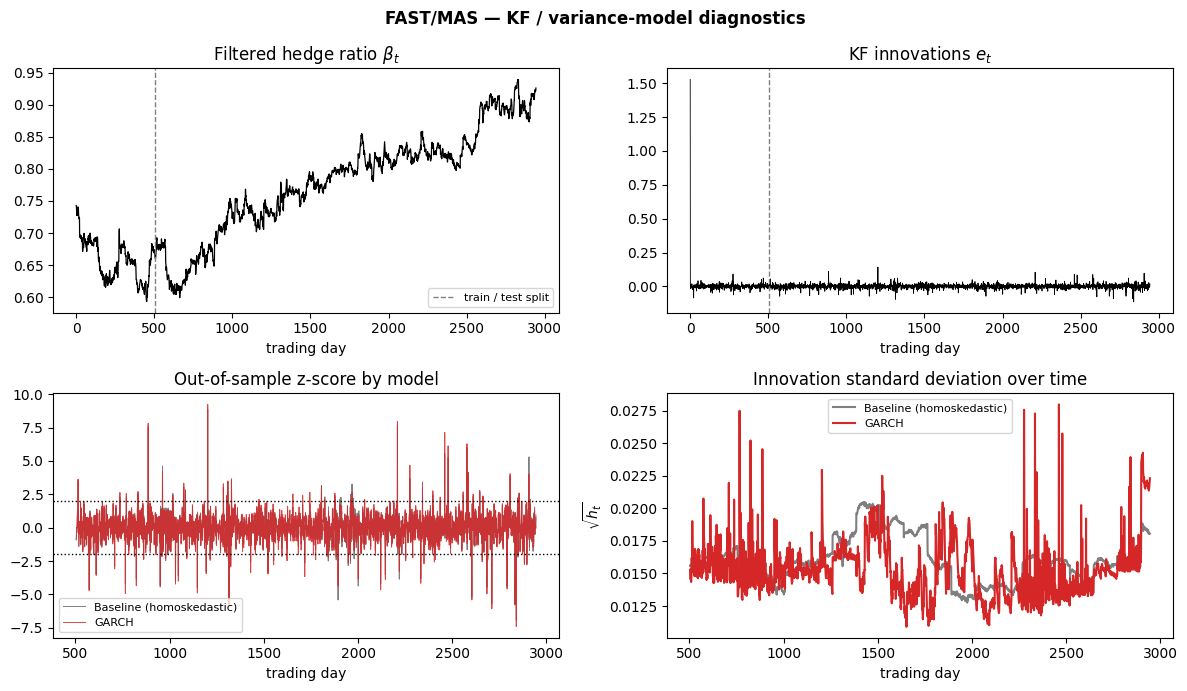

In [20]:
EXAMPLE_PAIR = next(iter(p for p in kf_results if f"{p[0]}/{p[1]}" in STRICT_PAIRS),
                     next(iter(kf_results)))
print(f"Representative pair used for the diagnostic panel below: {EXAMPLE_PAIR[0]}/{EXAMPLE_PAIR[1]}")


def plot_pair_diagnostics(pair, out, garch_h, train_window):
    y_t, x_t = pair
    n = len(out["e"])
    t_axis = np.arange(n)
    z_base = out["e"] / np.sqrt(out["S"])
    z_garch = out["e"] / np.sqrt(garch_h)

    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    fig.suptitle(f"{y_t}/{x_t} — KF / variance-model diagnostics", fontsize=12, fontweight="bold")

    axes[0, 0].plot(t_axis, out["beta_filt"], color="black", lw=0.9)
    axes[0, 0].axvline(train_window, color="grey", ls="--", lw=1, label="train / test split")
    axes[0, 0].set_title("Filtered hedge ratio $\\beta_t$")
    axes[0, 0].set_xlabel("trading day"); axes[0, 0].legend(fontsize=8)

    axes[0, 1].plot(t_axis, out["e"], color="black", lw=0.6)
    axes[0, 1].axvline(train_window, color="grey", ls="--", lw=1)
    axes[0, 1].set_title("KF innovations $e_t$")
    axes[0, 1].set_xlabel("trading day")

    oos = slice(train_window, n)
    axes[1, 0].plot(t_axis[oos], z_base[oos], label=MODEL_LABELS["base"], color=MODEL_COLORS["base"], lw=0.7)
    axes[1, 0].plot(t_axis[oos], z_garch[oos], label=MODEL_LABELS["garch"], color=MODEL_COLORS["garch"], lw=0.7, alpha=0.85)
    axes[1, 0].axhline(2, color="black", ls=":", lw=1); axes[1, 0].axhline(-2, color="black", ls=":", lw=1)
    axes[1, 0].legend(fontsize=8); axes[1, 0].set_title("Out-of-sample z-score by model")
    axes[1, 0].set_xlabel("trading day")

    axes[1, 1].plot(t_axis[oos], np.sqrt(out["S"][oos]), label=MODEL_LABELS["base"], color=MODEL_COLORS["base"])
    axes[1, 1].plot(t_axis[oos], np.sqrt(garch_h[oos]), label=MODEL_LABELS["garch"], color=MODEL_COLORS["garch"])
    axes[1, 1].legend(fontsize=8); axes[1, 1].set_title("Innovation standard deviation over time")
    axes[1, 1].set_xlabel("trading day"); axes[1, 1].set_ylabel("$\\sqrt{h_t}$")

    plt.tight_layout()
    plt.show()


plot_pair_diagnostics(EXAMPLE_PAIR, kf_results[EXAMPLE_PAIR], garch_results[EXAMPLE_PAIR], CONFIG["TRAIN_WINDOW"])


### Diagnostic: why does GARCH sometimes extend the drawdown duration?

`risk_comparison_table` (Section 7) shows GARCH lengthening `DrawdownDuration_days` relative to the
baseline for several pairs even where it shallows `MaxDrawdown` -- i.e. GARCH can trade a shorter,
deeper drawdown for a longer, shallower one. This is a diagnostic, not a fix: it looks at the single
pair where that effect is largest and compares the two models' trade logs (entries/exits and why
each position closed) during GARCH's single longest underwater stretch, to see whether the extra
time under water comes from more frequent re-entries, later exits, or something else.

Largest drawdown-duration REGRESSION: AMGN/LH (+556 trading days under water vs. baseline)

Baseline (homoskedastic): 101 trades -- {'reverted': np.int64(93), 'stop_loss': np.int64(8)}
GARCH: 126 trades -- {'reverted': np.int64(123), 'stop_loss': np.int64(3)}


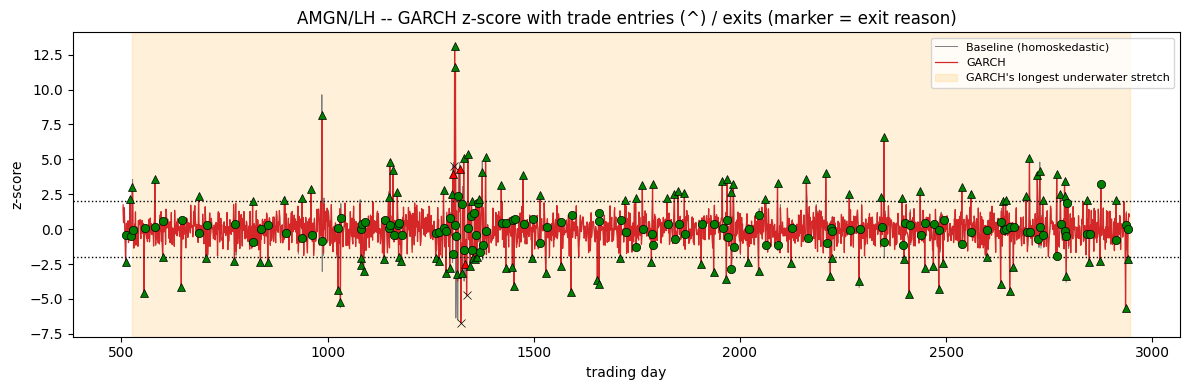

In [21]:
def longest_underwater_segment(equity):
    '''Start/end index (in the equity curve's own indexing) of its single longest stretch
    below the running peak -- the same quantity `drawdown_duration` measures the LENGTH of.'''
    eq = np.asarray(equity, dtype=float)
    peak = np.maximum.accumulate(eq)
    underwater = eq < peak
    best_len = best_start = cur_start = cur_len = 0
    for i, u in enumerate(underwater):
        if u:
            if cur_len == 0:
                cur_start = i
            cur_len += 1
            if cur_len > best_len:
                best_len, best_start = cur_len, cur_start
        else:
            cur_len = 0
    return best_start, best_start + best_len


if (risk_comparison_table["d_DrawdownDuration_days"] > 0).any():
    worst_row = risk_comparison_table.loc[risk_comparison_table["d_DrawdownDuration_days"].idxmax()]
    worst_pair_str = worst_row["pair"]
    worst_pair = next(p for p in kf_results if f"{p[0]}/{p[1]}" == worst_pair_str)

    print(f"Largest drawdown-duration REGRESSION: {worst_pair_str} "
          f"(+{worst_row['d_DrawdownDuration_days']:.0f} trading days under water vs. baseline)\n")

    for model in ["base", "garch"]:
        trades = trades_results[(worst_pair, model)]
        reasons = pd.Series([t[2] for t in trades]).value_counts()
        print(f"{MODEL_LABELS[model]}: {len(trades)} trades -- {dict(reasons)}")

    train_window = CONFIG["TRAIN_WINDOW"]
    eq_garch = backtest_results[(worst_pair, "garch")]["equity"]
    seg_start, seg_end = longest_underwater_segment(eq_garch)

    out = kf_results[worst_pair]
    n = len(out["e"])
    t_axis = np.arange(n)
    oos = slice(train_window, n)
    z_base_full = out["e"] / np.sqrt(out["S"])
    z_garch_full = out["e"] / np.sqrt(garch_results[worst_pair])

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(t_axis[oos], z_base_full[oos], color=MODEL_COLORS["base"], lw=0.7, label=MODEL_LABELS["base"])
    ax.plot(t_axis[oos], z_garch_full[oos], color=MODEL_COLORS["garch"], lw=0.9, label=MODEL_LABELS["garch"])
    ax.axhline(2, color="black", ls=":", lw=1); ax.axhline(-2, color="black", ls=":", lw=1)
    ax.axvspan(train_window + seg_start, train_window + seg_end, color="orange", alpha=0.15,
               label="GARCH's longest underwater stretch")

    marker_style = {"stop_loss": ("x", "red"), "reverted": ("o", "green"), "open_at_end": ("s", "grey")}
    for entry_idx, exit_idx, reason in trades_results[(worst_pair, "garch")]:
        mk, col = marker_style[reason]
        ax.plot(entry_idx, z_garch_full[entry_idx], marker="^", color=col, ms=6, mec="black", mew=0.5)
        ax.plot(exit_idx, z_garch_full[exit_idx], marker=mk, color=col, ms=6, mec="black", mew=0.5)

    ax.set_title(f"{worst_pair_str} -- GARCH z-score with trade entries (^) / exits (marker = exit reason)")
    ax.set_xlabel("trading day"); ax.set_ylabel("z-score")
    ax.legend(fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.show()
else:
    print("No pair shows a drawdown-duration regression under GARCH -- nothing to diagnose here.")


In [22]:
# --- Summary bar chart: average %% change in each risk metric (GARCH vs. baseline),
# aggregated across all selected pairs -- the single chart that answers "does the correction
# reduce risk, on average, across the universe tested".
agg_metrics = ["AnnualizedVol", "CVaR95"]  # MaxDrawdown/DrawdownDuration excluded here since their
                                            # "improvement" sign convention differs (see _risk_reduced
                                            # above) and would need separate handling in a %% change
pct_rows = []
for pair in risk_table["pair"].unique():
    base_row = risk_wide.loc[(pair, "base")]
    corr_row = risk_wide.loc[(pair, "garch")]
    for m in agg_metrics:
        if base_row[m] != 0:
            pct_change = 100 * (corr_row[m] - base_row[m]) / abs(base_row[m])
            pct_rows.append({"metric": m, "pct_change": pct_change})

pct_df = pd.DataFrame(pct_rows)
agg = pct_df.groupby("metric")["pct_change"].mean().reset_index()

fig = go.Figure()
fig.add_trace(go.Bar(x=agg["metric"], y=agg["pct_change"], name=MODEL_LABELS["garch"],
                      marker_color=MODEL_COLORS["garch"]))
fig.add_hline(y=0, line_color="black", line_width=1)
fig.update_layout(title="Average %% change vs. baseline, by risk metric (negative = risk reduced)".replace("%%", "%"),
                   yaxis_title="average %% change vs. baseline".replace("%%", "%"))
fig.show()


## 11. Summary table and next steps

`h1_table` summarizes the H1 diagnosis (ARCH/clustering). `calib_table` summarizes H2 (z-score
calibration, base vs. GARCH, GARCH tested against its own fitted distribution rather than assumed
Normal -- Section 5). `dm_table` (Section 6) is the QLIKE / Diebold-Mariano comparison of variance
*forecast accuracy* -- a narrower, better-powered question than H3, evaluated at daily granularity
rather than on the backtest. `risk_table`, `risk_comparison_table` and `sig_table` (plus the
Stouffer/sign pooled tests) are H3: a risk-only comparison of GARCH against the homoskedastic
baseline, with no P&L/Sharpe metric anywhere in the notebook. `strict_table` (Section 9) reruns the
H3 comparison, the H3 significance, and the Diebold-Mariano results, restricted to pairs that would
also survive a stricter `alpha=0.05` cointegration screen, as a check that results aren't an
artifact of the relaxed `COINT_ALPHA=0.10` used for pair selection.

**Not yet implemented in this version** (see the research plan): the EWMA benchmark and every
performance metric have been intentionally dropped to keep the comparison narrow (see the intro);
model 2 (Innovation-based Adaptive Estimation / Sage-Husa) and model 3 (GARCH-in-KF, estimated
jointly with the state) are also left for a follow-up version. Also still worth checking: the power
of the ARCH-LM test at the actual per-pair sample sizes, and the sensitivity of the risk-comparison
results to `TRAIN_WINDOW` / `REFIT_FREQ` / `COST_BPS` / `ENTRY_Z`/`EXIT_Z`/`STOP_Z` -- and, per the
Section 10 diagnostic, whether a cooldown period after a stop-loss exit would shorten GARCH's
drawdown durations without giving back its max-drawdown improvement.

In [23]:
print("=== H1 -- ARCH/clustering diagnosis ===")
display(h1_table)
print("\n=== H2 -- calibration (GARCH tested against its own fitted distribution) ===")
display(calib_table.sort_values(["pair", "model"]))
print("\n=== Section 6 -- QLIKE / Diebold-Mariano: variance forecast accuracy, GARCH vs. baseline ===")
display(dm_table)
print(f"Sign test: {k_better_dm}/{k_pairs_dm} pairs with lower GARCH QLIKE loss, "
      f"p={sign_test_dm_pvalue:.4f}  |  Stouffer Z={dm_stouffer_z:.3f}, p={dm_stouffer_p:.4f}")
print("\n=== H3 -- risk metrics: baseline vs. GARCH ===")
display(risk_table.sort_values(["pair", "model"]))
print("\n=== H3 -- risk comparison vs. baseline ===")
display(risk_comparison_table)
print("\n=== H3 -- significance of the volatility reduction vs. baseline (per-pair) ===")
display(sig_table)
print(f"\n=== H3 -- pooled significance across all {len(sig_table)} pairs ===")
print(f"Sign test: {k_reduced}/{k_pairs} pairs reduced, p={sign_test_pvalue:.4f}  |  "
      f"Stouffer Z={stouffer_z:.3f}, p={stouffer_p:.4f}")
print(f"\n=== Robustness: {len(STRICT_PAIRS)}/{len(kf_results)} pairs also pass alpha=0.05 ===")
display(strict_table)


=== H1 -- ARCH/clustering diagnosis ===


,pair,ARCH_LM_pvalue,ARCH_effect_significant_5pct
0,BAX/CI,1.630521e-06,True
1,AON/SPGI,3.092970e-59,True
2,CCI/PLD,1.079920e-30,True
3,MDT/RVTY,4.298150e-04,True
4,FAST/MAS,2.734352e-01,False
5,AMGN/LH,7.248413e-67,True
6,GD/NSC,4.577540e-05,True
7,GE/ITW,5.945848e-15,True
8,CCI/SPG,7.938664e-159,True



=== H2 -- calibration (GARCH tested against its own fitted distribution) ===


,pair,model,coverage_highvol,PIT_KS_stat,PIT_KS_pvalue
10,AMGN/LH,base,0.110565,0.072955,9.612723e-12
11,AMGN/LH,garch,0.104423,0.022947,1.505703e-01
2,AON/SPGI,base,0.105651,0.068332,2.355287e-10
3,AON/SPGI,garch,0.092138,0.014836,6.502291e-01
0,BAX/CI,base,0.100737,0.062804,8.193413e-09
1,BAX/CI,garch,0.082310,0.019409,3.126041e-01
4,CCI/PLD,base,0.125307,0.059431,6.163933e-08
5,CCI/PLD,garch,0.088452,0.026939,5.681159e-02
16,CCI/SPG,base,0.144963,0.070839,4.266381e-11
17,CCI/SPG,garch,0.077396,0.015908,5.616407e-01



=== Section 6 -- QLIKE / Diebold-Mariano: variance forecast accuracy, GARCH vs. baseline ===


...

,pair,d_AnnualizedVol,AnnualizedVol_reduced,d_MaxDrawdown,MaxDrawdown_reduced,d_DrawdownDuration_days,DrawdownDuration_days_reduced,d_CVaR95,CVaR95_reduced
0,BAX/CI,0.002186,False,0.025901,True,-65.0,True,-0.000455,True
1,AON/SPGI,-0.005403,True,0.001054,True,20.0,False,0.000084,False
2,CCI/PLD,-0.012024,True,-0.011025,False,275.0,False,-0.001028,True
3,MDT/RVTY,-0.002157,True,0.011019,True,312.0,False,0.000558,False
4,FAST/MAS,0.000394,False,-0.021782,False,0.0,False,-0.000235,True
5,AMGN/LH,0.010141,False,0.017915,True,556.0,False,0.002515,False
6,GD/NSC,0.011704,False,0.087816,True,0.0,False,0.000596,False
7,GE/ITW,-0.017254,True,0.206307,True,-393.0,True,-0.003525,True
8,CCI/SPG,-0.042570,True,0.011270,True,0.0,False,-0.005012,True



=== H3 -- significance of the volatility reduction vs. baseline (per-pair) ===


,pair,vol_diff,vol_reduction_pvalue,vol_reduction_significant_5pct
0,BAX/CI,0.000138,0.643,False
1,AON/SPGI,-0.000340,0.157,False
2,CCI/PLD,-0.000757,0.012,True
3,MDT/RVTY,-0.000136,0.155,False
4,FAST/MAS,0.000025,0.563,False
5,AMGN/LH,0.000639,0.997,False
6,GD/NSC,0.000737,0.915,False
7,GE/ITW,-0.001087,0.003,True
8,CCI/SPG,-0.002682,0.044,True



=== H3 -- pooled significance across all 9 pairs ===
Sign test: 5/9 pairs reduced, p=0.5000  |  Stouffer Z=1.363, p=0.0865

=== Robustness: 2/9 pairs also pass alpha=0.05 ===


,pair,passes_strict_alpha_0.05
0,BAX/CI,False
1,AON/SPGI,False
2,CCI/PLD,False
3,MDT/RVTY,False
4,FAST/MAS,True
5,AMGN/LH,False
6,GD/NSC,False
7,GE/ITW,True
8,CCI/SPG,False
